# Folding Validation

In [60]:
import pandas as pd

csu_df = pd.read_parquet('csu_uc_salary_schedule_2013-2024.parquet')
csu_df = csu_df.loc[csu_df['source_system'].eq('CSU')].copy()
csu_df.head()

,year,campus,name,title,role,original_department,department,gross_pay,base_pay,overtime_pay,...,Step 29,Step 30,Step 31,Step 32,salary_match,salary_schedule_year,salary_range_mean,salary_low,salary_high,salary_expected
0,2013,CSU Bakersfield,Abbas Grammy,Professor Emeritus,ladder_faculty,Economics,"Business, Economics & Finance",148840,97454,0,...,NaN,NaN,NaN,NaN,both,2024.0,13041.5,103116.0,209880.0,156498.0
1,2014,CSU Bakersfield,Abbas Grammy,Professor Emeritus,ladder_faculty,Economics,"Business, Economics & Finance",164953,98207,0,...,NaN,NaN,NaN,NaN,both,2024.0,13041.5,103116.0,209880.0,156498.0
2,2015,CSU Bakersfield,Abbas Grammy,Professor Emeritus,ladder_faculty,Economics,"Business, Economics & Finance",155361,100861,0,...,NaN,NaN,NaN,NaN,both,2024.0,13041.5,103116.0,209880.0,156498.0
3,2016,CSU Bakersfield,Abbas Grammy,Professor Emeritus,ladder_faculty,Economics,"Business, Economics & Finance",146317,102539,0,...,NaN,NaN,NaN,NaN,both,2024.0,13041.5,103116.0,209880.0,156498.0
4,2016,CSU Bakersfield,Abbas Grammy,Professor Emeritus,supplemental_teaching_pay,Economics,"Business, Economics & Finance",0,0,0,...,NaN,NaN,NaN,NaN,left_only,2024.0,<NA>,<NA>,<NA>,<NA>


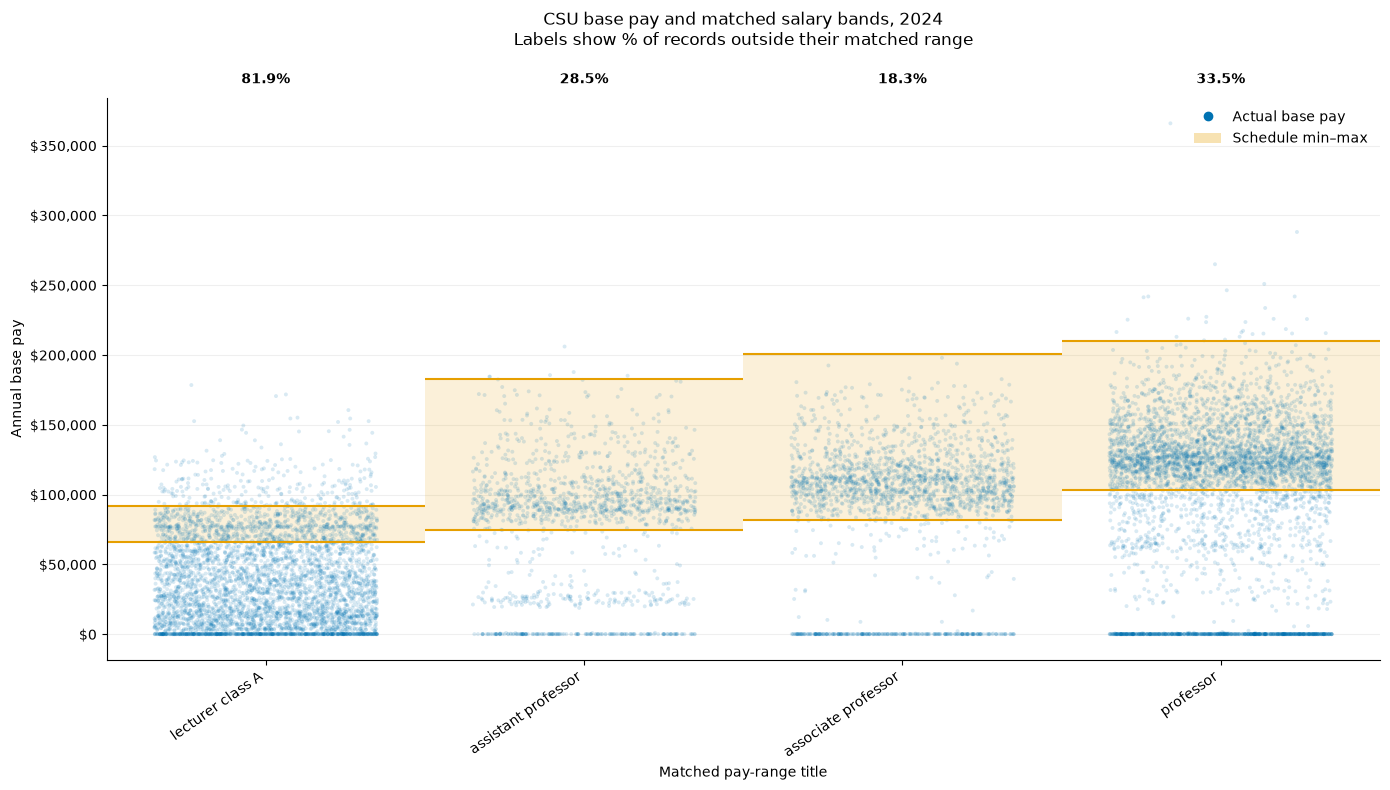

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

plot_df = csu_df.loc[csu_df['year'].eq(2024)].dropna(
    subset=['matched_rank', 'base_pay', 'salary_low', 'salary_high']
).copy()

plot_df['outside'] = (
    (plot_df['base_pay'] < plot_df['salary_low'])
    | (plot_df['base_pay'] > plot_df['salary_high'])
)

order = plot_df.groupby('matched_rank')['base_pay'].median().sort_values().index
# Hide Instructor in the chart; retain the underlying records.
order = order[order.str.casefold() != 'instructor']
rng = np.random.default_rng(42)

fig, ax = plt.subplots(figsize=(14, 8))

for i, title in enumerate(order):
    group = plot_df[plot_df['matched_rank'] == title]

    # Each schedule band fills the category width.
    bounds = group[['salary_low', 'salary_high']].drop_duplicates()
    for low, high in bounds.itertuples(index=False, name=None):
        ax.fill_between(
            [i - 0.5, i + 0.5], low, high,
            color='#E69F00', alpha=0.15, linewidth=0,
        )
        ax.hlines([low, high], i - 0.5, i + 0.5,
                  color='#E69F00', linewidth=1.5)

    x = i + rng.uniform(-0.35, 0.35, len(group))
    ax.scatter(x, group['base_pay'], s=8, alpha=0.15,
               color='#0072B2', edgecolors='none', rasterized=True)

    outside_pct = 100 * group['outside'].mean()
    ax.text(i, 1.02, f'{outside_pct:.1f}%',
            transform=ax.get_xaxis_transform(),
            ha='center', va='bottom', fontweight='bold')

ax.set_xticks(range(len(order)), order, rotation=35, ha='right')
ax.set_xlim(-0.5, len(order) - 0.5)
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax.set(xlabel='Matched pay-range title', ylabel='Annual base pay')
ax.set_title(
    'CSU base pay and matched salary bands, 2024\n'
    'Labels show % of records outside their matched range',
    pad=38,
)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.2)
ax.spines[['top', 'right']].set_visible(False)

ax.legend(handles=[
    Line2D([], [], marker='o', linestyle='', color='#0072B2',
           label='Actual base pay'),
    Patch(facecolor='#E69F00', alpha=0.3, label='Schedule min–max'),
], frameon=False)

plt.tight_layout()
plt.show()

In [62]:
# Examine zero base pay in 2024.
data_2024 = csu_df.loc[csu_df['year'].eq(2024)]
zeros = data_2024.loc[data_2024['base_pay'].eq(0)]

print(f"Zero base pay: {len(zeros):,} of {len(data_2024):,} records "
      f"({len(zeros) / len(data_2024):.1%})")
print(f"Zero base pay with positive gross pay: {zeros['gross_pay'].gt(0).sum():,}")

display(
    zeros.groupby(['source_system', 'role'], dropna=False)
    .size().rename('zero_base_pay_records')
    .sort_values(ascending=False).to_frame()
)

display(
    zeros[['campus', 'name', 'title', 'matched_rank',
           'base_pay', 'gross_pay', 'other_pay', 'overtime_pay']]
    .head(30)
)

Zero base pay: 7,091 of 18,793 records (37.7%)
Zero base pay with positive gross pay: 64


zero_base_pay_records
source_system role                                                  
CSU           supplemental_teaching_pay                         5319
              ladder_faculty                                    1244
              lecturer                                           522
              researcher_specialist_librarian                      6

,campus,name,title,matched_rank,base_pay,gross_pay,other_pay,overtime_pay
32,CSU Bakersfield,Abigael Flachmann,Lecturer in English,None,0,0,0,0
39,CSU Bakersfield,Abolfazl Kiani,Lecturer in Chemistry and Biochemistry,None,0,0,0,0
56,CSU Bakersfield,Adam Sawyer,Professor,None,0,0,0,0
62,CSU Bakersfield,Adelmira Ynostroza Ochoa,Professor,None,0,0,0,0
77,CSU Bakersfield,Alberto Cruz,Professor,None,0,0,0,0
106,CSU Bakersfield,Alemseghed Kebede,Professor,None,0,0,0,0
142,CSU Bakersfield,Alice Hays,Professor,None,0,0,0,0
162,CSU Bakersfield,Allison Evans Fluckey,Lecturer in Psychology,None,0,0,0,0
193,CSU Bakersfield,Amber Stokes,Professor,None,0,0,0,0
210,CSU Bakersfield,Amy Gancarz-Kausch,Professor,None,0,0,0,0


Some low 2024 base pay amounts may reflect someone leaving partway through the year. We flag cases below the salary minimum where pay dropped at least 25% and fell more than two standard deviations below their prior average. The baseline uses at least three positive-pay years from 2019-2023 within the same campus, matched rank, and salary range, with payroll lines summed for each year. The 25% cutoff helps avoid flagging small drops for people with very steady pay. These are possible departures to review, not confirmed cases.

In [63]:
def flag_possible_departures(df, year=2024, min_years=3, min_drop=0.25):
    # Sum payroll lines within each person, rank, and schedule range.
    keys = ['campus', 'name', 'matched_rank', 'salary_low', 'salary_high']
    data = df.loc[df['source_system'].eq('CSU')].dropna(
        subset=keys + ['base_pay']
    )

    annual = (
        data.groupby(keys + ['year'], as_index=False)['base_pay'].sum()
    )

    # Use positive base pay from the previous five years as the baseline.
    history = annual.loc[
        annual['year'].between(year - 5, year - 1)
        & annual['base_pay'].gt(0)
    ]
    baseline = history.groupby(keys, as_index=False).agg(
        prior_years=('base_pay', 'size'),
        prior_mean=('base_pay', 'mean'),
        prior_std=('base_pay', 'std'),
    )

    result = annual.loc[annual['year'].eq(year)].merge(
        baseline, on=keys, how='left', validate='one_to_one'
    )

    result['drop_pct'] = 100 * (
        1 - result['base_pay'] / result['prior_mean']
    )
    result['below_min'] = result['base_pay'] < result['salary_low']
    result['possible_departure'] = (
        result['below_min']
        & result['prior_years'].ge(min_years)
        & result['base_pay'].lt(
            result['prior_mean'] - 2 * result['prior_std']
        )
        & result['drop_pct'].ge(100 * min_drop)
    )

    return result.sort_values('drop_pct', ascending=False)


departure_check = flag_possible_departures(csu_df)

display(
    departure_check.loc[departure_check['possible_departure'], [
        'campus', 'name', 'matched_rank', 'base_pay', 'salary_low',
        'prior_years', 'prior_mean', 'prior_std', 'drop_pct'
    ]].round(1)
)

,campus,name,matched_rank,base_pay,salary_low,prior_years,prior_mean,prior_std,drop_pct
54,CSU Bakersfield,Chia Thao,lecturer class A,0,66084.0,4.0,11732.8,1788.6,100.0
7784,"California State University, Sacramento",Anne Lindsay,associate professor,0,81900.0,5.0,85072.8,7034.5,100.0
10257,San Francisco State University,Theresa Roeder,professor,0,103116.0,4.0,162960.8,6772.7,100.0
10145,San Francisco State University,Paul Ellison,lecturer class A,0,66084.0,5.0,40017.2,6174.6,100.0
10171,San Francisco State University,Rita Melendez,professor,0,103116.0,5.0,111029.6,11343.0,100.0
...,...,...,...,...,...,...,...,...,...
7917,"California State University, Sacramento",Edward Baranowski,professor,75689,103116.0,5.0,102243.2,4307.9,26.0
9909,San Francisco State University,Greta Snider,professor,79299,103116.0,5.0,106869.4,4452.8,25.8
599,CSU Channel Islands,Suzanne Soule,lecturer class A,39079,66084.0,5.0,52234.0,3742.3,25.2
9087,San Diego State University,Joseph Waters,professor,79387,103116.0,5.0,105931.4,4299.7,25.1


This view highlights possible departures in pink. Percentages compare all 2024 annual records with the records left after excluding flagged cases; both the outside count and denominator are recalculated. Each point sums base pay within a person, campus, matched rank, and salary range, so these percentages can differ from the earlier payroll-line chart. Records without enough history stay included. A flag is a possible explanation, not confirmation of departure.

Excluding possible departures lowers the percentage of 2024 annual base-pay records outside their matched salary range:

| Matched rank | Before | After |
| --- | ---: | ---: |
| Lecturer class A | 81.1% | 80.2% |
| Assistant professor | 20.9% | 19.8% |
| Associate professor | 7.5% | 5.4% |
| Professor | 24.1% | 19.6% |

Professors show the largest decrease, at 4.5 percentage points. Pink crosses mark the flagged cases in the chart below. These figures use annual base-pay totals, and the flags indicate possible departures rather than confirmed ones.


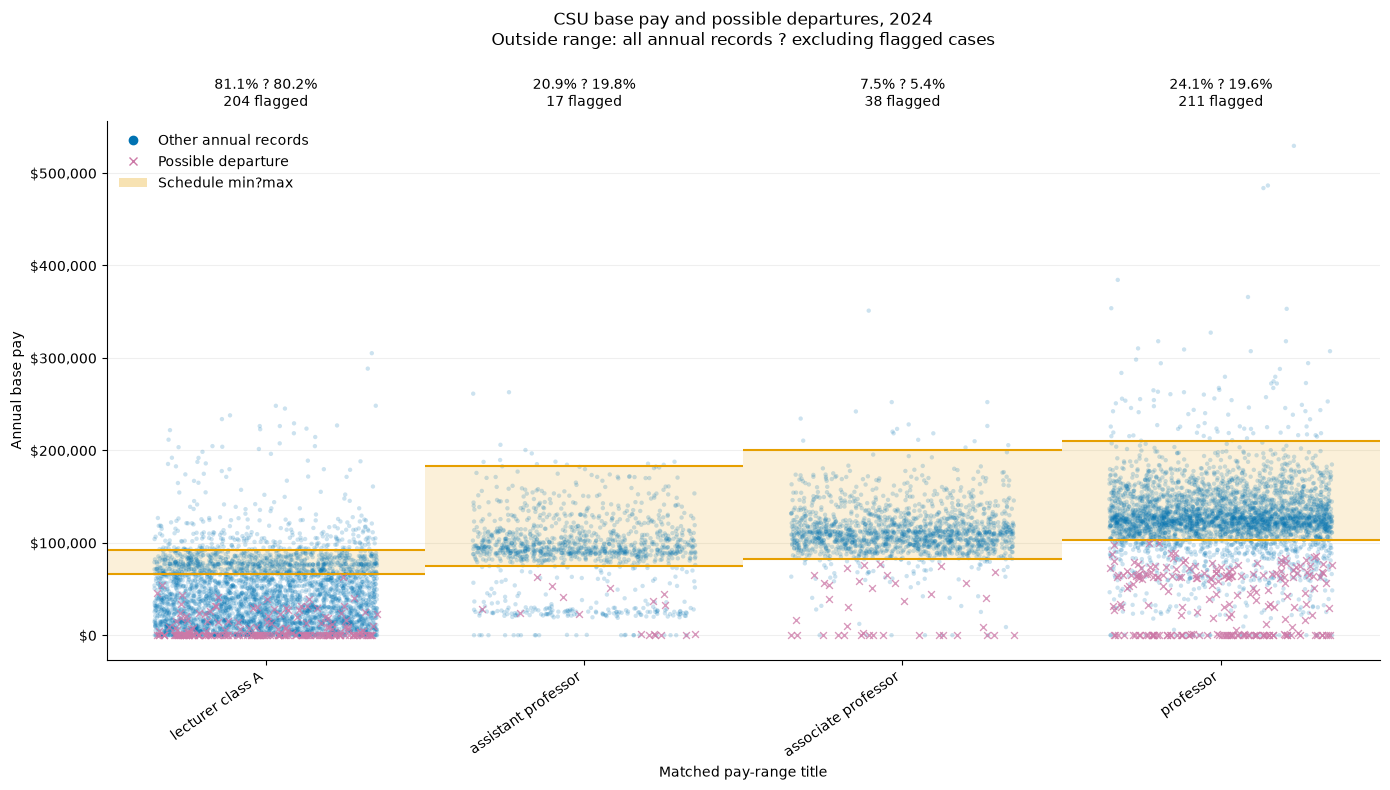

,annual_records,possible_departures,outside_before_pct,outside_after_pct,change_pp
matched_rank,,,,,
lecturer class A,4254,204,81.1,80.2,-0.9
assistant professor,1220,17,20.9,19.8,-1.1
associate professor,1677,38,7.5,5.4,-2.1
professor,3774,211,24.1,19.6,-4.5


In [64]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Use the same 2024 annual totals as the departure detector.
plot_df = departure_check.copy()
plot_df['outside'] = (
    plot_df['base_pay'].lt(plot_df['salary_low'])
    | plot_df['base_pay'].gt(plot_df['salary_high'])
)
order = plot_df.groupby('matched_rank')['base_pay'].median().sort_values().index
# Hide Instructor in the chart; retain the underlying records.
order = order[order.str.casefold() != 'instructor']
rng = np.random.default_rng(42)
summary_rows = []
fig, ax = plt.subplots(figsize=(14, 8))

for i, title in enumerate(order):
    group = plot_df.loc[plot_df['matched_rank'].eq(title)]
    flagged = group['possible_departure']
    remaining = group.loc[~flagged]
    before = 100 * group['outside'].mean()
    after = 100 * remaining['outside'].mean()
    summary_rows.append({
        'matched_rank': title,
        'annual_records': len(group),
        'possible_departures': int(flagged.sum()),
        'outside_before_pct': before,
        'outside_after_pct': after,
        'change_pp': after - before,
    })

    bounds = group[['salary_low', 'salary_high']].drop_duplicates()
    for low, high in bounds.itertuples(index=False, name=None):
        ax.fill_between([i - 0.5, i + 0.5], low, high,
                        color='#E69F00', alpha=0.15, linewidth=0)
        ax.hlines([low, high], i - 0.5, i + 0.5,
                  color='#E69F00', linewidth=1.5)

    x = i + rng.uniform(-0.35, 0.35, len(group))
    ax.scatter(x[~flagged.to_numpy()], group.loc[~flagged, 'base_pay'],
               s=10, alpha=0.2, color='#0072B2', edgecolors='none',
               rasterized=True)
    ax.scatter(x[flagged.to_numpy()], group.loc[flagged, 'base_pay'],
               s=24, alpha=0.75, color='#CC79A7', marker='x', linewidths=1,
               rasterized=True, zorder=3)

    after_label = f'{after:.1f}%' if len(remaining) else 'N/A'
    ax.text(i, 1.02, f'{before:.1f}% ? {after_label}\n{int(flagged.sum()):,} flagged',
            transform=ax.get_xaxis_transform(), ha='center', va='bottom',
            fontsize=10)

ax.set_xticks(range(len(order)), order, rotation=35, ha='right')
ax.set_xlim(-0.5, len(order) - 0.5)
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax.set(xlabel='Matched pay-range title', ylabel='Annual base pay')
ax.set_title(
    'CSU base pay and possible departures, 2024\n'
    'Outside range: all annual records ? excluding flagged cases', pad=55
)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.2)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(handles=[
    Line2D([], [], marker='o', linestyle='', color='#0072B2',
           label='Other annual records'),
    Line2D([], [], marker='x', linestyle='', color='#CC79A7',
           label='Possible departure'),
    Patch(facecolor='#E69F00', alpha=0.3, label='Schedule min?max'),
], frameon=False)
plt.tight_layout()
plt.show()

outside_summary = pd.DataFrame(summary_rows).set_index('matched_rank')
display(outside_summary.round(1))


In [77]:
# Repeated names at the same university within the same year.
# These can be separate payroll lines, so inspect before removing anything.
keys = ['year', 'campus', 'name','base_pay']
duplicate_counts = (
    csu_df.groupby(keys, dropna=False).size().rename('records').reset_index()
)
duplicate_counts = duplicate_counts.loc[duplicate_counts['records'].gt(1)]
duplicate_2024 = duplicate_counts.loc[duplicate_counts['year'].eq(2024)]

print(f"Repeated name/university/year groups across all years: {len(duplicate_counts):,}")
print(f"Repeated name/university groups in 2024: {len(duplicate_2024):,}")
print(f"2024 records in these groups: {duplicate_2024['records'].sum():,}")
print(f"2024 rows beyond one per group: {(duplicate_2024['records'] - 1).sum():,}")

display(duplicate_2024.sort_values('records', ascending=False).head(30))

# Show the underlying rows for the five most repeated 2024 names.
examples = duplicate_2024.nlargest(5, 'records')
duplicate_details = csu_df.merge(examples, on=keys, how='inner', validate='many_to_one')
display(duplicate_details[
    keys + ['title', 'role', 'department', 'base_pay', 'gross_pay', 'records']
].sort_values(keys + ['title']))


Repeated name/university/year groups across all years: 7,230
Repeated name/university groups in 2024: 1,062
2024 records in these groups: 2,213
2024 rows beyond one per group: 1,151


,year,campus,name,base_pay,records
147305,2024,Sonoma State University,Jacquelyn Guilford,0,8
131796,2024,CSU Long Beach,Nat Hansuvadha,0,6
140101,2024,"California State University, Fresno",Larissa Dr Mercado-Lopez,0,6
131011,2024,CSU Long Beach,Angela Locks,0,4
143846,2024,San Diego State University,Anna Kim,0,4
147260,2024,Sonoma State University,Elizabeth Stanny,0,4
144145,2024,San Diego State University,Drew Thomases,0,4
147187,2024,Sonoma State University,Ayumi Nagase,0,4
139764,2024,"California State University, Fresno",Catherine Rose,0,4
134873,2024,Cal Poly Humboldt,Daniel Barton,0,4


ValueError: The column label 'base_pay' is not unique.

This separate view uses individual 2024 payroll records. Orange downward triangles mark repeated name/university groups below range, and purple upward triangles mark those above range, only when at least one record in the same group falls within its own matched range. Green points show the in-range companions; other records stay gray. Each record is checked against its own salary bounds, even if a person has different matched ranks. These are repeated payroll records, not confirmed errors; nothing is removed.

Labels show the outside-range percentage before and after excluding only the highlighted out-of-range records. The adjusted percentage recalculates both the outlier count and total record count; in-range companions stay included. This is a sensitivity check, not confirmation that the excluded payroll records are errors.

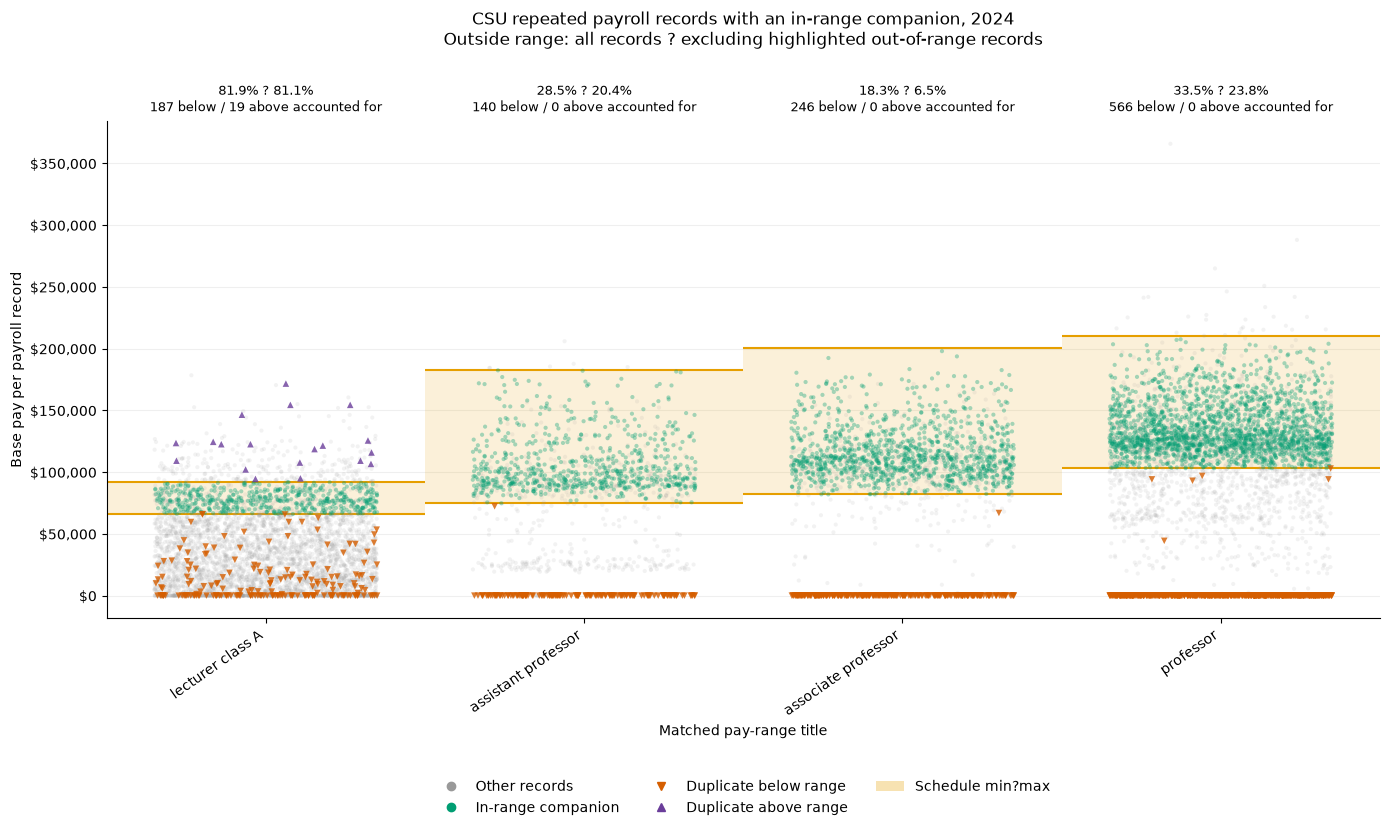

status,Other records,In-range companion,Duplicate below range,Duplicate above range
matched_rank,,,,
lecturer class A,3905,519,187,19
assistant professor,548,689,140,0
associate professor,580,1115,246,0
professor,1912,1992,566,0


,records_before,accounted_for_records,records_after,outside_before_pct,outside_after_pct,change_pp
matched_rank,,,,,,
lecturer class A,4630,206,4424,81.9,81.1,-0.8
assistant professor,1377,140,1237,28.5,20.4,-8.1
associate professor,1941,246,1695,18.3,6.5,-11.9
professor,4470,566,3904,33.5,23.8,-9.6


In [66]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Use individual payroll records so repeated payments remain separate points.
keys = ['year', 'campus', 'name']
data_2024 = csu_df.loc[csu_df['year'].eq(2024)].copy()
data_2024['group_records'] = data_2024.groupby(keys, dropna=False)['year'].transform('size')
duplicate_plot_df = data_2024.dropna(
    subset=['matched_rank', 'base_pay', 'salary_low', 'salary_high']
).copy()
duplicate_plot_df['in_range'] = duplicate_plot_df['base_pay'].between(
    duplicate_plot_df['salary_low'], duplicate_plot_df['salary_high']
)
duplicate_plot_df['has_in_range'] = duplicate_plot_df.groupby(
    keys, dropna=False
)['in_range'].transform('any')
eligible = duplicate_plot_df['group_records'].gt(1) & duplicate_plot_df['has_in_range']
duplicate_plot_df['status'] = 'Other records'
duplicate_plot_df.loc[eligible & duplicate_plot_df['in_range'], 'status'] = 'In-range companion'
duplicate_plot_df.loc[
    eligible & duplicate_plot_df['base_pay'].lt(duplicate_plot_df['salary_low']), 'status'
] = 'Duplicate below range'
duplicate_plot_df.loc[
    eligible & duplicate_plot_df['base_pay'].gt(duplicate_plot_df['salary_high']), 'status'
] = 'Duplicate above range'

duplicate_plot_df['outside'] = ~duplicate_plot_df['in_range']
duplicate_plot_df['accounted_for'] = duplicate_plot_df['status'].isin(
    ['Duplicate below range', 'Duplicate above range']
)

order = duplicate_plot_df.groupby('matched_rank')['base_pay'].median().sort_values().index
# Hide Instructor in the chart; retain the underlying records.
order = order[order.str.casefold() != 'instructor']
rng = np.random.default_rng(42)
styles = [
    ('Other records', '#999999', 'o', 0.12),
    ('In-range companion', '#009E73', 'o', 0.35),
    ('Duplicate below range', '#D55E00', 'v', 0.8),
    ('Duplicate above range', '#6A3D9A', '^', 0.8),
]
percentage_rows = []
fig, ax = plt.subplots(figsize=(14, 9))
for i, title in enumerate(order):
    group = duplicate_plot_df.loc[duplicate_plot_df['matched_rank'].eq(title)]
    for low, high in group[['salary_low', 'salary_high']].drop_duplicates().itertuples(index=False, name=None):
        ax.fill_between([i - 0.5, i + 0.5], low, high,
                        color='#E69F00', alpha=0.15, linewidth=0)
        ax.hlines([low, high], i - 0.5, i + 0.5, color='#E69F00', linewidth=1.5)
    x = i + rng.uniform(-0.35, 0.35, len(group))
    for label, color, marker, alpha in styles:
        mask = group['status'].eq(label)
        ax.scatter(x[mask.to_numpy()], group.loc[mask, 'base_pay'],
                   color=color, marker=marker, alpha=alpha,
                   s=22 if 'Duplicate' in label else 9, edgecolors='none',
                   rasterized=True, zorder=3 if 'Duplicate' in label else 2)
    below = group['status'].eq('Duplicate below range').sum()
    above = group['status'].eq('Duplicate above range').sum()
    remaining = group.loc[~group['accounted_for']]
    before = 100 * group['outside'].mean()
    after = 100 * remaining['outside'].mean()
    percentage_rows.append({
        'matched_rank': title,
        'records_before': len(group),
        'accounted_for_records': int(group['accounted_for'].sum()),
        'records_after': len(remaining),
        'outside_before_pct': before,
        'outside_after_pct': after,
        'change_pp': after - before,
    })
    after_label = f'{after:.1f}%' if len(remaining) else 'N/A'
    ax.text(i, 1.02, f'{before:.1f}% ? {after_label}\n'
            f'{below:,} below / {above:,} above accounted for',
            transform=ax.get_xaxis_transform(), ha='center', fontsize=9)

ax.set_xticks(range(len(order)), order, rotation=35, ha='right')
ax.set_xlim(-0.5, len(order) - 0.5)
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax.set(xlabel='Matched pay-range title', ylabel='Base pay per payroll record')
ax.set_title(
    'CSU repeated payroll records with an in-range companion, 2024\n'
    'Outside range: all records ? excluding highlighted out-of-range records', pad=55
)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.2)
ax.spines[['top', 'right']].set_visible(False)
handles = [Line2D([], [], marker=marker, linestyle='', color=color, label=label)
           for label, color, marker, _ in styles]
handles.append(Patch(facecolor='#E69F00', alpha=0.3, label='Schedule min?max'))
ax.legend(handles=handles, frameon=False, loc='upper center',
          bbox_to_anchor=(0.5, -0.3), ncol=3)
plt.tight_layout()
plt.show()

# Counts of highlighted individual payroll records by matched rank.
duplicate_range_summary = pd.crosstab(
    duplicate_plot_df['matched_rank'], duplicate_plot_df['status']
).reindex(index=order, columns=[s[0] for s in styles], fill_value=0)
display(duplicate_range_summary)

# Adjusted percentages exclude highlighted out-of-range records from both counts.
duplicate_outlier_summary = pd.DataFrame(percentage_rows).set_index('matched_rank')
display(duplicate_outlier_summary.round(1))


This view combines the two checks on individual 2024 payroll records. Pink crosses mark possible departures, orange triangles mark out-of-range duplicate-group records with an in-range companion, and purple diamonds mark both. Departure flags are calculated from annual totals and carried back to their component payroll records. The adjusted percentage excludes outside-range records with either flag, counting overlaps once and recalculating the denominator. In-range companions remain included. These are possible explanations, not confirmed departures or data errors; the earlier departure-only chart uses annual totals and therefore has different starting percentages.

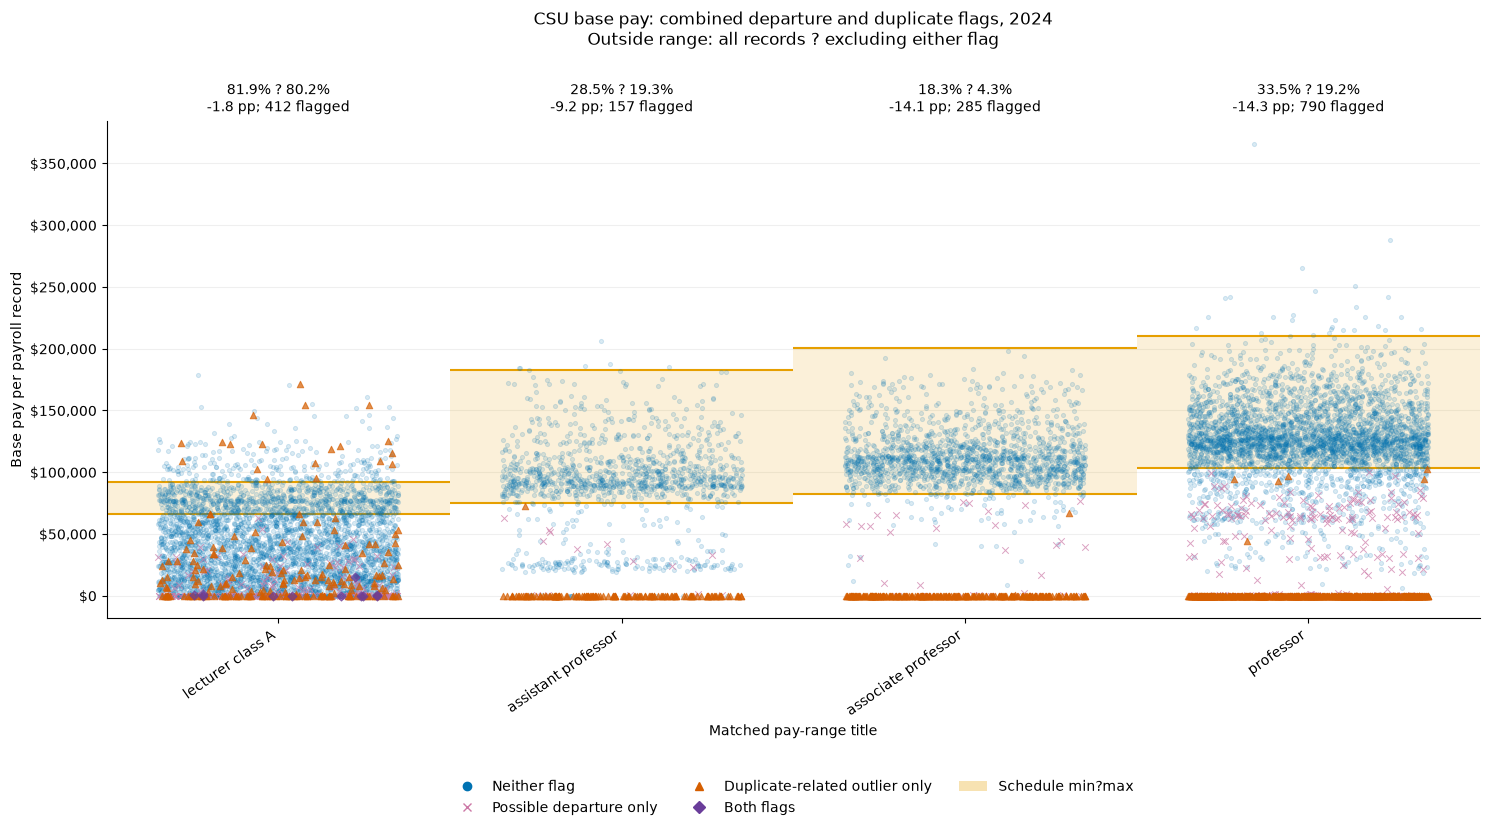

,payroll_records,departure_records,duplicate_outliers,both_flags,excluded_once,remaining_records,outside_before_pct,after_departures_pct,after_duplicates_pct,after_either_pct,change_pp
matched_rank,,,,,,,,,,,
lecturer class A,4630,217,206,11,412,4218,81.9,81.0,81.1,80.2,-1.8
assistant professor,1377,17,140,0,157,1220,28.5,27.6,20.4,19.3,-9.2
associate professor,1941,39,246,0,285,1656,18.3,16.7,6.5,4.3,-14.1
professor,4470,224,566,0,790,3680,33.5,30.0,23.8,19.2,-14.3


In [67]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Keep individual payroll records, as in the duplicate-companion chart.
keys = ['year', 'campus', 'name', 'matched_rank', 'salary_low', 'salary_high']
combined_plot_df = duplicate_plot_df.merge(
    departure_check[keys + ['possible_departure']],
    on=keys, how='left', validate='many_to_one',
)
combined_plot_df['departure_flag'] = (
    combined_plot_df['possible_departure'].fillna(False).astype(bool)
    & combined_plot_df['outside']
)
combined_plot_df['duplicate_flag'] = combined_plot_df['accounted_for']
combined_plot_df['either_flag'] = (
    combined_plot_df['departure_flag'] | combined_plot_df['duplicate_flag']
)

styles = [
    (False, False, '#0072B2', 'o', 'Neither flag'),
    (True, False, '#CC79A7', 'x', 'Possible departure only'),
    (False, True, '#D55E00', '^', 'Duplicate-related outlier only'),
    (True, True, '#6A3D9A', 'D', 'Both flags'),
]
order = combined_plot_df.groupby('matched_rank')['base_pay'].median().sort_values().index
# Hide Instructor in the chart; retain the underlying records.
order = order[order.str.casefold() != 'instructor']
rng = np.random.default_rng(42)
combined_rows = []
fig, ax = plt.subplots(figsize=(15, 9))

for i, title in enumerate(order):
    group = combined_plot_df.loc[combined_plot_df['matched_rank'].eq(title)]
    departure = group['departure_flag']
    duplicate = group['duplicate_flag']
    flagged = group['either_flag']
    remaining = group.loc[~flagged]
    before = 100 * group['outside'].mean()
    after = 100 * remaining['outside'].mean()
    combined_rows.append({
        'matched_rank': title,
        'payroll_records': len(group),
        'departure_records': int(departure.sum()),
        'duplicate_outliers': int(duplicate.sum()),
        'both_flags': int((departure & duplicate).sum()),
        'excluded_once': int(flagged.sum()),
        'remaining_records': len(remaining),
        'outside_before_pct': before,
        'after_departures_pct': 100 * group.loc[~departure, 'outside'].mean(),
        'after_duplicates_pct': 100 * group.loc[~duplicate, 'outside'].mean(),
        'after_either_pct': after,
        'change_pp': after - before,
    })

    for low, high in group[['salary_low', 'salary_high']].drop_duplicates().itertuples(index=False, name=None):
        ax.fill_between([i - 0.5, i + 0.5], low, high,
                        color='#E69F00', alpha=0.15, linewidth=0)
        ax.hlines([low, high], i - 0.5, i + 0.5, color='#E69F00', linewidth=1.5)

    x = i + rng.uniform(-0.35, 0.35, len(group))
    for dep, dup, color, marker, label in styles:
        mask = departure.eq(dep) & duplicate.eq(dup)
        ax.scatter(x[mask.to_numpy()], group.loc[mask, 'base_pay'],
                   s=22 if dep or dup else 9, alpha=0.7 if dep or dup else 0.15,
                   color=color, marker=marker, linewidths=0.7,
                   rasterized=True, zorder=3 if dep or dup else 2)

    after_label = f'{after:.1f}%' if len(remaining) else 'N/A'
    change_label = f'{after - before:+.1f} pp' if len(remaining) else 'N/A'
    ax.text(i, 1.02, f'{before:.1f}% ? {after_label}\n'
            f'{change_label}; {int(flagged.sum()):,} flagged',
            transform=ax.get_xaxis_transform(), ha='center', fontsize=10)

ax.set_xticks(range(len(order)), order, rotation=35, ha='right')
ax.set_xlim(-0.5, len(order) - 0.5)
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax.set(xlabel='Matched pay-range title', ylabel='Base pay per payroll record')
ax.set_title(
    'CSU base pay: combined departure and duplicate flags, 2024\n'
    'Outside range: all records ? excluding either flag', pad=55
)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.2)
ax.spines[['top', 'right']].set_visible(False)
handles = [Line2D([], [], marker=marker, linestyle='', color=color, label=label)
           for _, _, color, marker, label in styles]
handles.append(Patch(facecolor='#E69F00', alpha=0.3, label='Schedule min?max'))
ax.legend(handles=handles, frameon=False, loc='upper center',
          bbox_to_anchor=(0.5, -0.3), ncol=3)
plt.tight_layout()
plt.show()

combined_outlier_summary = pd.DataFrame(combined_rows).set_index('matched_rank')
display(combined_outlier_summary.round(1))


Remaining out-of-range payroll records in 2024: 4,393
Percentages show each university's share of all remaining outliers, not its own outlier rate.


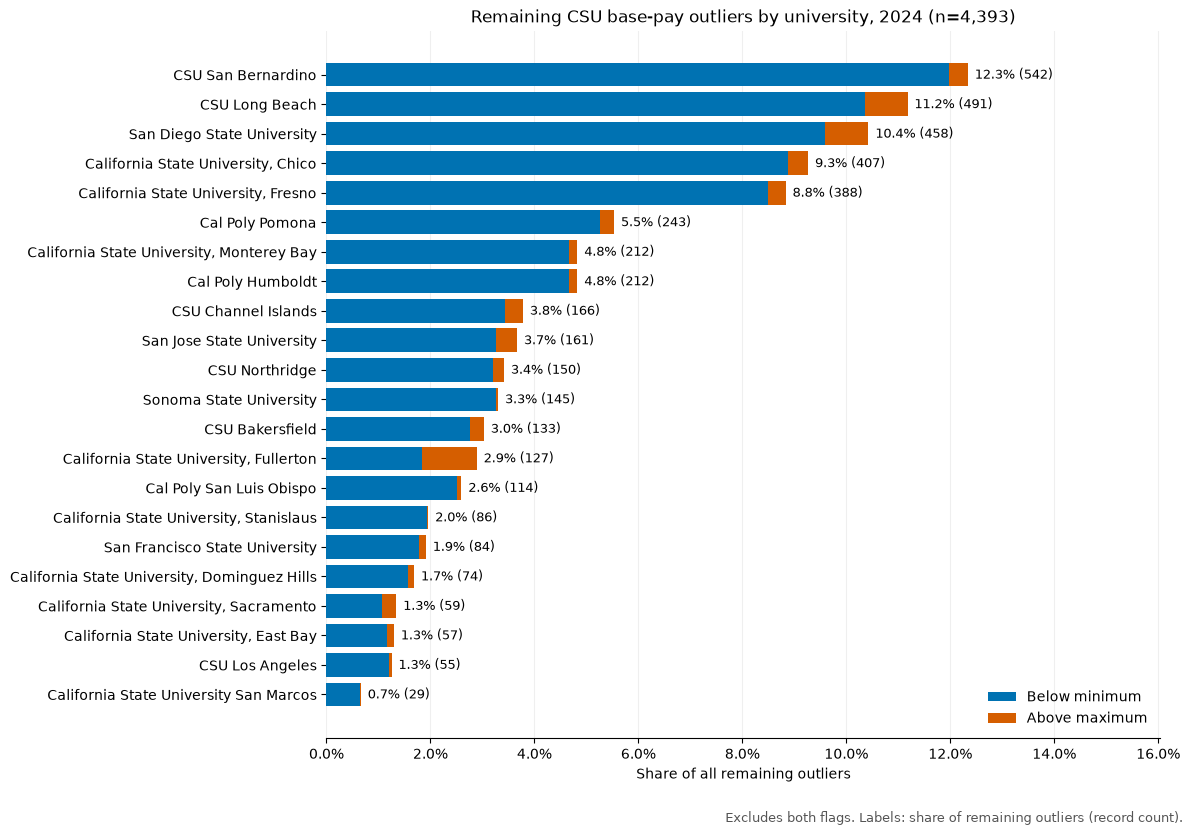

In [68]:
# Remaining 2024 outliers after excluding possible departures and duplicate-related cases.
remaining_outliers = combined_plot_df.loc[
    combined_plot_df['outside'] & ~combined_plot_df['either_flag']
].copy()
remaining_outliers['below_min'] = (
    remaining_outliers['base_pay'] < remaining_outliers['salary_low']
)
remaining_outliers['above_max'] = (
    remaining_outliers['base_pay'] > remaining_outliers['salary_high']
)

outliers_by_university = remaining_outliers.groupby('campus', dropna=False).agg(
    remaining_outliers=('base_pay', 'size'),
    below_min=('below_min', 'sum'),
    above_max=('above_max', 'sum'),
)
total_remaining = len(remaining_outliers)
outliers_by_university['pct_of_remaining_outliers'] = (
    100 * outliers_by_university['remaining_outliers'] / total_remaining
    if total_remaining else 0.0
)
outliers_by_university = outliers_by_university.sort_values(
    'remaining_outliers', ascending=False
)

print(f'Remaining out-of-range payroll records in 2024: {total_remaining:,}')
print("Percentages show each university's share of all remaining outliers, not its own outlier rate.")
# Each bar shows a university's share of all remaining outliers.
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

chart = outliers_by_university.sort_values('remaining_outliers')
if total_remaining:
    below_share = 100 * chart['below_min'] / total_remaining
    above_share = 100 * chart['above_max'] / total_remaining
    fig, ax = plt.subplots(figsize=(12, max(5, len(chart) * 0.38)))
    ax.barh(chart.index, below_share, color='#0072B2', label='Below minimum')
    ax.barh(chart.index, above_share, left=below_share,
            color='#D55E00', label='Above maximum')
    for i, (_, row) in enumerate(chart.iterrows()):
        ax.annotate(
            f"{row['pct_of_remaining_outliers']:.1f}% ({int(row['remaining_outliers']):,})",
            (row['pct_of_remaining_outliers'], i),
            xytext=(5, 0), textcoords='offset points', va='center', fontsize=9,
        )
    ax.set_xlim(0, chart['pct_of_remaining_outliers'].max() * 1.3)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.set(
        xlabel='Share of all remaining outliers', ylabel='',
        title=f'Remaining CSU base-pay outliers by university, 2024 (n={total_remaining:,})',
    )
    ax.set_axisbelow(True)
    ax.grid(axis='x', alpha=0.2)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.legend(frameon=False, loc='lower right')
    fig.text(0.99, 0.01,
             'Excludes both flags. Labels: share of remaining outliers (record count).',
             ha='right', fontsize=9, color='#555555')
    plt.tight_layout(rect=[0, 0.04, 1, 1])
    plt.show()
else:
    print('No remaining outliers to plot.')


# Individual records remain available in remaining_outliers.


### Dataset count versus expected CSU count

This mirrors the count-and-join logic in `ss_comms_audit.ipynb` using the full 2024 CSU population. Campus names are mapped to the reference CSV, and lecturer class A is grouped as lecturer. Actual counts count non-missing name records, not unique people, without excluding departure or duplicate flags. Rank counts include four reference categories; total counts also include instructors and missing ranks. Expected professor counts use tenure-track categories, so these comparisons do not establish that the populations are identical. CSU Los Angeles is included with its matching reference campus.


In [69]:
from pathlib import Path
import pandas as pd

# Match ss_comms_audit: full 2024 CSU population, counting non-missing names.
# These are payroll-record counts, not unique people or outlier-filtered counts.
reference_path = next(
    folder / 'Data-Folding' / 'csu_faculty_count_by_campus.csv'
    for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / 'Data-Folding' / 'csu_faculty_count_by_campus.csv').is_file()
)
expected_faculty_counts = pd.read_csv(reference_path)
if expected_faculty_counts['campus'].duplicated().any():
    raise ValueError('Expected counts must have one row per campus.')

campus_mapping = {'Bakersfield': 'CSU Bakersfield',
 'Channel Islands': 'CSU Channel Islands',
 'Chico': 'California State University, Chico',
 'Dominguez Hills': 'California State University, Dominguez Hills',
 'East Bay': 'California State University, East Bay',
 'Fresno': 'California State University, Fresno',
 'Fullerton': 'California State University, Fullerton',
 'Humboldt': 'Cal Poly Humboldt',
 'Long Beach': 'CSU Long Beach',
 'Los Angeles': 'CSU Los Angeles',
 'Monterey Bay': 'California State University, Monterey Bay',
 'Northridge': 'CSU Northridge',
 'Pomona': 'Cal Poly Pomona',
 'Sacramento': 'California State University, Sacramento',
 'San Bernardino': 'CSU San Bernardino',
 'San Diego': 'San Diego State University',
 'San Francisco': 'San Francisco State University',
 'San Jose': 'San Jose State University',
 'San Luis Obispo': 'Cal Poly San Luis Obispo',
 'San Marcos': 'California State University San Marcos',
 'Sonoma': 'Sonoma State University',
 'Stanislaus': 'California State University, Stanislaus'}
reverse_campus_mapping = {full: short for short, full in campus_mapping.items()}
folding_faculty_labels = csu_df.loc[
    csu_df['source_system'].eq('CSU') & csu_df['year'].eq(2024),
    ['campus', 'matched_rank', 'name'],
].copy()
folding_faculty_labels['matched_rank'] = (
    folding_faculty_labels['matched_rank'].astype('string').str.strip().str.casefold()
    .replace({'a': 'lecturer', 'range a': 'lecturer', 'lecturer class a': 'lecturer'})
)
folding_faculty_labels['count_campus_name'] = (
    folding_faculty_labels['campus'].map(reverse_campus_mapping)
)
faculty_rank_mapping = {
    'assistant professor': 'tenure_track_assistant_professor',
    'associate professor': 'tenure_track_associate_professor',
    'professor': 'tenure_track_professor',
    'lecturer': 'lecturer_total',
}

# Preserve rows without a comparable campus/rank for inspection.
folding_rank_unmatched = folding_faculty_labels.loc[
    ~folding_faculty_labels['matched_rank'].isin(faculty_rank_mapping)
    | folding_faculty_labels['count_campus_name'].isna()
].copy()
print(f'Records without a comparable campus/rank: {len(folding_rank_unmatched):,}')
display(folding_rank_unmatched['matched_rank'].value_counts(dropna=False))
if folding_faculty_labels['count_campus_name'].isna().any():
    raise ValueError('Some CSU campuses need a reference-name mapping.')

folding_expected_rank_counts = expected_faculty_counts.melt(
    id_vars='campus', value_vars=list(faculty_rank_mapping.values()),
    var_name='matched_rank', value_name='expected_count',
)
folding_expected_rank_counts['matched_rank'] = folding_expected_rank_counts['matched_rank'].map(
    {column: rank for rank, column in faculty_rank_mapping.items()}
)
folding_campus_rank_counts = (
    folding_faculty_labels.loc[folding_faculty_labels['matched_rank'].isin(faculty_rank_mapping)]
    .groupby(['count_campus_name', 'matched_rank'])['name'].count().rename('count')
)
# Keep zero observed counts for every reference rank at each campus in the data.
campus_rank_index = pd.MultiIndex.from_product(
    [sorted(folding_faculty_labels['count_campus_name'].unique()), list(faculty_rank_mapping)],
    names=['count_campus_name', 'matched_rank'],
)
folding_campus_rank_counts = folding_campus_rank_counts.reindex(
    campus_rank_index, fill_value=0
).reset_index().join(
    folding_expected_rank_counts.set_index(['campus', 'matched_rank']),
    on=['count_campus_name', 'matched_rank'], validate='many_to_one',
)
folding_campus_totals = (
    folding_faculty_labels.groupby('count_campus_name')['name'].count().rename('count').to_frame()
    .join(expected_faculty_counts.set_index('campus')['all_faculty'].rename('expected_count'),
          validate='one_to_one')
    .sort_values('expected_count', ascending=False)
)
for comparison in [folding_campus_rank_counts, folding_campus_totals]:
    comparison['expected_count'] = pd.to_numeric(comparison['expected_count'], errors='raise')
    if comparison['expected_count'].isna().any():
        raise ValueError('Some campuses or ranks have no expected count.')

print(f"2024 named payroll records: {folding_campus_totals['count'].sum():,}")
print(f"Expected faculty across the same campuses: {folding_campus_totals['expected_count'].sum():,}")
display(folding_campus_totals)
display(folding_campus_rank_counts)


Records without a comparable campus/rank: 6,375


matched_rank
<NA>          6374
instructor       1
Name: count, dtype: Int64

2024 named payroll records: 18,793
Expected faculty across the same campuses: 26,517


,count,expected_count
count_campus_name,,
Long Beach,1405,2451
Fullerton,1487,2233
San Diego,1927,2133
San Jose,726,2016
Northridge,838,1991
Sacramento,1175,1618
San Luis Obispo,1002,1559
Fresno,928,1432
Pomona,974,1354


,count_campus_name,matched_rank,count,expected_count
0,Bakersfield,assistant professor,0,57
1,Bakersfield,associate professor,0,85
2,Bakersfield,professor,230,89
3,Bakersfield,lecturer,87,367
4,Channel Islands,assistant professor,6,33
...,...,...,...,...
83,Sonoma,lecturer,164,180
84,Stanislaus,assistant professor,6,54
85,Stanislaus,associate professor,3,79
86,Stanislaus,professor,2,166


### Dataset count versus expected CSU count, accounting for repeated names

Totals count distinct names per campus in 2024, so multiple payroll lines for the same name at the same university count once. Rank counts also count each name once within a campus/rank. A name appearing under multiple ranks can appear in multiple rank categories, so those categories need not sum to the distinct-name total; these cases are retained in `audit_multi_rank_names`. The audit campus and reference-rank mappings are retained (21 campuses; Los Angeles unmapped), but counting distinct names replaces the audit's payroll-record counting rule. Instructors and missing ranks remain in totals. Different people sharing a name can be combined because no employee ID is available. No departure flags are excluded.

In [70]:
# Use the audit campus/rank mapping, with unique-name counts to avoid repeated payroll rows.
# Do not apply the audit's commented-out canon filters.
audit_campus_mapping = {'Bakersfield': 'CSU Bakersfield',
 'Channel Islands': 'CSU Channel Islands',
 'Chico': 'California State University, Chico',
 'Dominguez Hills': 'California State University, Dominguez Hills',
 'East Bay': 'California State University, East Bay',
 'Fresno': 'California State University, Fresno',
 'Fullerton': 'California State University, Fullerton',
 'Humboldt': 'Cal Poly Humboldt',
 'Long Beach': 'CSU Long Beach',
 'Los Angeles': None,
 'Monterey Bay': 'California State University, Monterey Bay',
 'Northridge': 'CSU Northridge',
 'Pomona': 'Cal Poly Pomona',
 'Sacramento': 'California State University, Sacramento',
 'San Bernardino': 'CSU San Bernardino',
 'San Diego': 'San Diego State University',
 'San Francisco': 'San Francisco State University',
 'San Jose': 'San Jose State University',
 'San Luis Obispo': 'Cal Poly San Luis Obispo',
 'San Marcos': 'California State University San Marcos',
 'Sonoma': 'Sonoma State University',
 'Stanislaus': 'California State University, Stanislaus'}
audit_reverse_campus_mapping = {
    full: short for short, full in audit_campus_mapping.items() if full is not None
}
audit_folding_labels = csu_df.loc[
    csu_df['source_system'].eq('CSU') & csu_df['year'].eq(2024),
    ['campus', 'matched_rank', 'name'],
].copy()
# Folding uses a different display label for the audit's lecturer default A.
audit_folding_labels['matched_rank'] = (
    audit_folding_labels['matched_rank'].astype('string').str.strip().str.casefold()
    .replace({'a': 'lecturer', 'range a': 'lecturer', 'lecturer class a': 'lecturer'})
)
audit_folding_labels['count_campus_name'] = (
    audit_folding_labels['campus'].map(audit_reverse_campus_mapping)
)
audit_reference_counts = expected_faculty_counts.copy()
audit_rank_mapping = {
    'assistant professor': 'tenure_track_assistant_professor',
    'associate professor': 'tenure_track_associate_professor',
    'professor': 'tenure_track_professor',
    'lecturer': 'lecturer_total',
}
audit_rank_unmatched = audit_folding_labels.loc[
    ~audit_folding_labels['matched_rank'].isin(audit_rank_mapping)
    | audit_folding_labels['count_campus_name'].isna()
].copy()
audit_expected_rank_counts = audit_reference_counts.melt(
    id_vars='campus', value_vars=list(audit_rank_mapping.values()),
    var_name='matched_rank', value_name='expected_count',
)
audit_expected_rank_counts['matched_rank'] = audit_expected_rank_counts['matched_rank'].map(
    {column: rank for rank, column in audit_rank_mapping.items()}
)
audit_rank_index = pd.MultiIndex.from_product(
    [sorted(audit_folding_labels['count_campus_name'].dropna().unique()), list(audit_rank_mapping)],
    names=['count_campus_name', 'matched_rank'],
)
audit_folding_rank_counts = (
    audit_folding_labels.loc[audit_folding_labels['matched_rank'].isin(audit_rank_mapping)]
    .groupby(['count_campus_name', 'matched_rank'])['name'].nunique().rename('count')
    .reindex(audit_rank_index, fill_value=0).reset_index()
    .join(audit_expected_rank_counts.set_index(['campus', 'matched_rank']),
          on=['count_campus_name', 'matched_rank'], validate='many_to_one')
)
if audit_folding_rank_counts['expected_count'].isna().any():
    raise ValueError('Some displayed campus/rank combinations have no expected count.')
print(f"2024 records outside the audit campus mapping: {audit_folding_labels['count_campus_name'].isna().sum():,}")
# Retain ambiguous rank assignments for inspection instead of choosing a rank.
audit_multi_rank_names = (
    audit_folding_labels.loc[audit_folding_labels['matched_rank'].isin(audit_rank_mapping)]
    .groupby(['count_campus_name', 'name'])['matched_rank'].nunique()
)
audit_multi_rank_names = audit_multi_rank_names.loc[audit_multi_rank_names.gt(1)]
print('Totals count each name once per campus; rank counts count each name once per campus/rank.')
print(f'Name/campus groups appearing in multiple reference ranks: {len(audit_multi_rank_names):,}')


def audit_campus_unique_counts(labels, reference):
    """Shared counting rule for the position chart and university gap chart."""
    totals = (
        labels.groupby('count_campus_name')['name'].nunique().rename('count').to_frame()
        .join(reference.set_index('campus')['all_faculty'].rename('expected_count'),
              validate='one_to_one')
        .sort_values('expected_count', ascending=False)
    )
    if totals.empty or totals['expected_count'].isna().any():
        raise ValueError('Expected counts are required for every displayed campus.')
    return totals


2024 records outside the audit campus mapping: 583
Totals count each name once per campus; rank counts count each name once per campus/rank.
Name/campus groups appearing in multiple reference ranks: 207


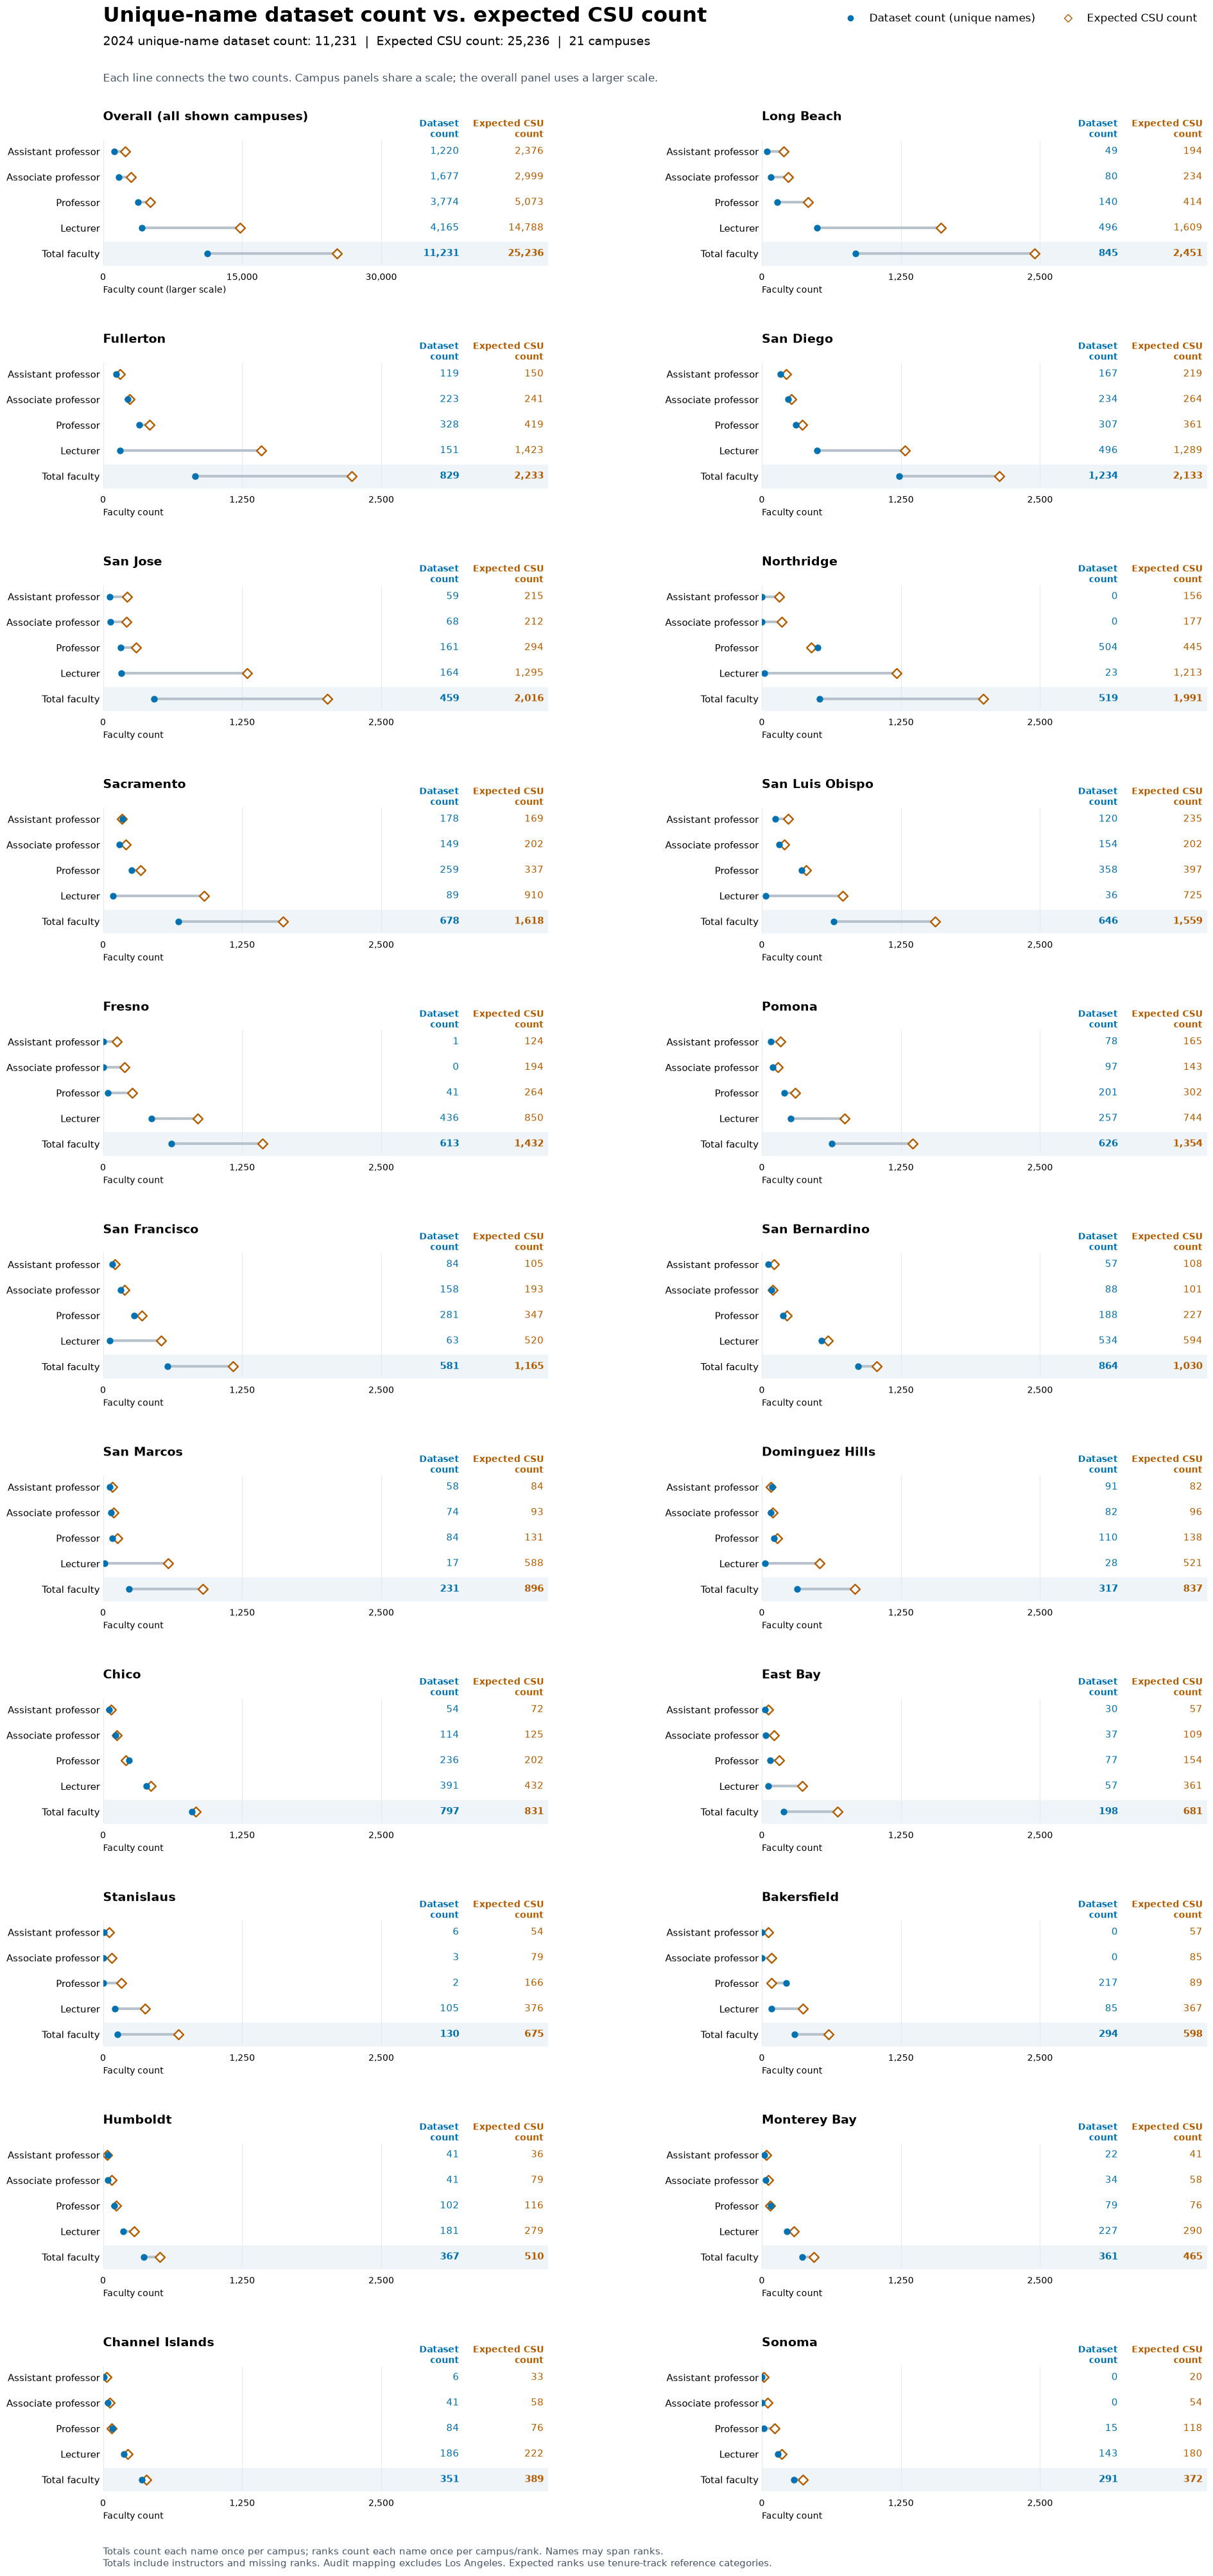

In [71]:
# Dataset and expected CSU counts, using the active ss_comms_audit rules.
# Connected dots emphasize actual-versus-expected gaps; consistent scales and
# exact-value columns support comparison without overlapping point labels.
# Design reference: https://www.datawrapper.de/academy/how-to-create-a-range-plot
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import StrMethodFormatter
import numpy as np

audit_folding_comparison_totals = audit_campus_unique_counts(
    audit_folding_labels, audit_reference_counts
)

rank_order = list(audit_rank_mapping)
row_labels = ['Assistant professor', 'Associate professor', 'Professor', 'Lecturer', 'Total faculty']
campuses = audit_folding_comparison_totals.index.tolist()
# Add an overall summary for exactly the campuses displayed.
panel_names = ['Overall'] + campuses
nrows = (len(panel_names) + 1) // 2
fig, axes = plt.subplots(nrows, 2, figsize=(20, nrows * 3.5 + 2), squeeze=False)
actual_color, expected_color = '#0072B2', '#B35C00'
scale_max = max(audit_folding_comparison_totals.max().max(),
                audit_folding_rank_counts[['count', 'expected_count']].max().max())
scale_max = max(100, np.ceil(scale_max / 500) * 500)
y = np.arange(5)

for ax, campus in zip(axes.flat, panel_names):
    if campus == 'Overall':
        values = audit_folding_rank_counts.loc[
            audit_folding_rank_counts['count_campus_name'].isin(campuses)
        ].groupby('matched_rank')[['count', 'expected_count']].sum().reindex(rank_order)
        totals = audit_folding_comparison_totals[['count', 'expected_count']].sum()
    else:
        values = audit_folding_rank_counts.loc[
            audit_folding_rank_counts['count_campus_name'].eq(campus)
        ].set_index('matched_rank').reindex(rank_order)
        totals = audit_folding_comparison_totals.loc[campus]
    actual = np.append(values['count'].to_numpy(), totals['count'])
    expected = np.append(values['expected_count'].to_numpy(), totals['expected_count'])
    # Overall needs a larger, explicitly labeled scale to preserve campus detail.
    panel_max = (max(1000, np.ceil(max(actual.max(), expected.max()) / 5000) * 5000)
                 if campus == 'Overall' else scale_max)
    ax.axhspan(3.55, 4.45, color='#EFF4F8', zorder=0)
    ax.hlines(y, np.minimum(actual, expected), np.maximum(actual, expected),
              color='#B8C2CC', linewidth=3, zorder=2)
    ax.scatter(expected, y, s=58, marker='D', facecolors='white',
               edgecolors=expected_color, linewidths=1.7, zorder=3)
    ax.scatter(actual, y, s=42, color=actual_color, zorder=4)
    ax.set_yticks(y, row_labels, fontsize=11)
    ax.set_ylim(4.65, -0.8)
    # Reserve a separate area for exact counts; labels never compete with dots.
    ax.set_xlim(0, panel_max * 1.60)
    ax.set_xticks([0, panel_max / 2, panel_max])
    ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    ax.vlines([0, panel_max / 2, panel_max], -0.45, 4.4,
              colors='#E2E8F0', linewidth=0.7, zorder=1)
    for xpos, label, color in [(0.80, 'Dataset\ncount', actual_color), (0.99, 'Expected CSU\ncount', expected_color)]:
        ax.text(xpos, -0.56, label, transform=ax.get_yaxis_transform(),
                ha='right', fontsize=10, fontweight='bold', color=color)
    for row, (observed, reference) in enumerate(zip(actual, expected)):
        weight = 'bold' if row == 4 else 'normal'
        ax.text(0.80, row, f'{observed:,.0f}', transform=ax.get_yaxis_transform(),
                ha='right', va='center', fontsize=11, color=actual_color, fontweight=weight)
        ax.text(0.99, row, f'{reference:,.0f}', transform=ax.get_yaxis_transform(),
                ha='right', va='center', fontsize=11, color=expected_color, fontweight=weight)
    ax.set_title('Overall (all shown campuses)' if campus == 'Overall' else campus,
                 loc='left', fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('Faculty count (larger scale)' if campus == 'Overall' else 'Faculty count',
                  fontsize=10, loc='left')
    ax.tick_params(axis='both', length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

for ax in list(axes.flat)[len(panel_names):]:
    ax.set_visible(False)

fig.suptitle('Unique-name dataset count vs. expected CSU count',
             x=0.12, y=0.993, ha='left', fontsize=23, fontweight='bold')
fig.text(0.12, 0.978,
         f'2024 unique-name dataset count: {audit_folding_comparison_totals["count"].sum():,.0f}  |  '
         f'Expected CSU count: {audit_folding_comparison_totals["expected_count"].sum():,.0f}  |  {len(campuses)} campuses',
         fontsize=14)
fig.text(0.12, 0.964,
         'Each line connects the two counts. Campus panels share a scale; the overall panel uses a larger scale.',
         fontsize=12, color='#475569')
fig.legend(handles=[
    Line2D([], [], marker='o', linestyle='none', color=actual_color, label='Dataset count (unique names)'),
    Line2D([], [], marker='D', linestyle='none', markerfacecolor='white',
           markeredgecolor=expected_color, label='Expected CSU count')
], loc='upper right', bbox_to_anchor=(0.98, 0.994), ncol=2, frameon=False, fontsize=12)
fig.text(0.12, 0.008,
         'Totals count each name once per campus; ranks count each name once per campus/rank. Names may span ranks.\n'
         'Totals include instructors and missing ranks. Audit mapping excludes Los Angeles. Expected ranks use tenure-track reference categories.',
         fontsize=11, color='#475569')
fig.subplots_adjust(left=0.12, right=0.98, top=0.945, bottom=0.035,
                    hspace=0.60, wspace=0.48)
# Optional export for reading at full size:
# fig.savefig('faculty_counts_two_columns.pdf', bbox_inches='tight')
plt.show()


In [72]:
tc_df = pd.read_parquet(
    'transparent_california_no_dup_filtered_csu_salaries_2013-2024 (1).parquet'
)

print(f'{len(tc_df):,} records')
print(tc_df.columns.tolist())
display(tc_df.head(20))

896,675 records
['name', 'job', 'department', 'base', 'overtime', 'other', 'benefitshw', 'totalpay', 'totalbenefits', 'totalpaybenefits', 'notes', 'year', 'agency', 'status', 'role']


,name,job,department,base,overtime,other,benefitshw,totalpay,totalbenefits,totalpaybenefits,notes,year,agency,status,role
0,Alice Burton,accountant i,None,47604,0,125,None,47729,17489,65218,None,2013,california state university,None,staff
1,Dagoberto Escobedo,accountant i,None,48131,0,0,None,48131,18163,66294,None,2013,california state university,None,staff
2,Alyssa Kanzaki,accountant i,None,42598,0,0,None,42598,13774,56372,None,2013,california state university,None,staff
3,Terri Porter,accountant i,None,46100,0,0,None,46100,30051,76152,None,2013,california state university,None,staff
4,Cynthia Williams,accountant i,None,50576,0,475,None,51051,30982,82034,None,2013,california state university,None,staff
5,Silvia Aguilar,accountant ii,None,41003,0,2671,None,43674,28520,72194,None,2013,california state university,None,staff
6,June Cacho,accountant ii,None,54492,0,725,None,55217,19304,74521,None,2013,california state university,None,staff
7,Criselle Espiritu,accountant ii,None,59380,0,0,None,59380,20609,79990,None,2013,california state university,None,staff
8,Cindy Gong,accountant ii,None,55202,0,400,None,55602,19074,74676,None,2013,california state university,None,staff
9,Abigail Herrera,accountant ii,None,60720,0,-80,None,60640,16800,77440,None,2013,california state university,None,staff


### CSU-wide unique-name counts, 2024

Repeated payroll rows now count once per name and campus in the folded data. Flags are aggregated with any: a person is highlighted if any of their payroll records has that flag, and overlap is counted once. All 22 campuses are included in this system-wide view. TC uses matching roles and distinct names CSU-wide because the source has no campus field; identical names at different campuses can therefore be combined. TC role counts can overlap. Expected counts are faculty headcounts with an unverified reference year. These name-based counts are closer to a headcount than payroll-row totals but are not employee-ID counts.

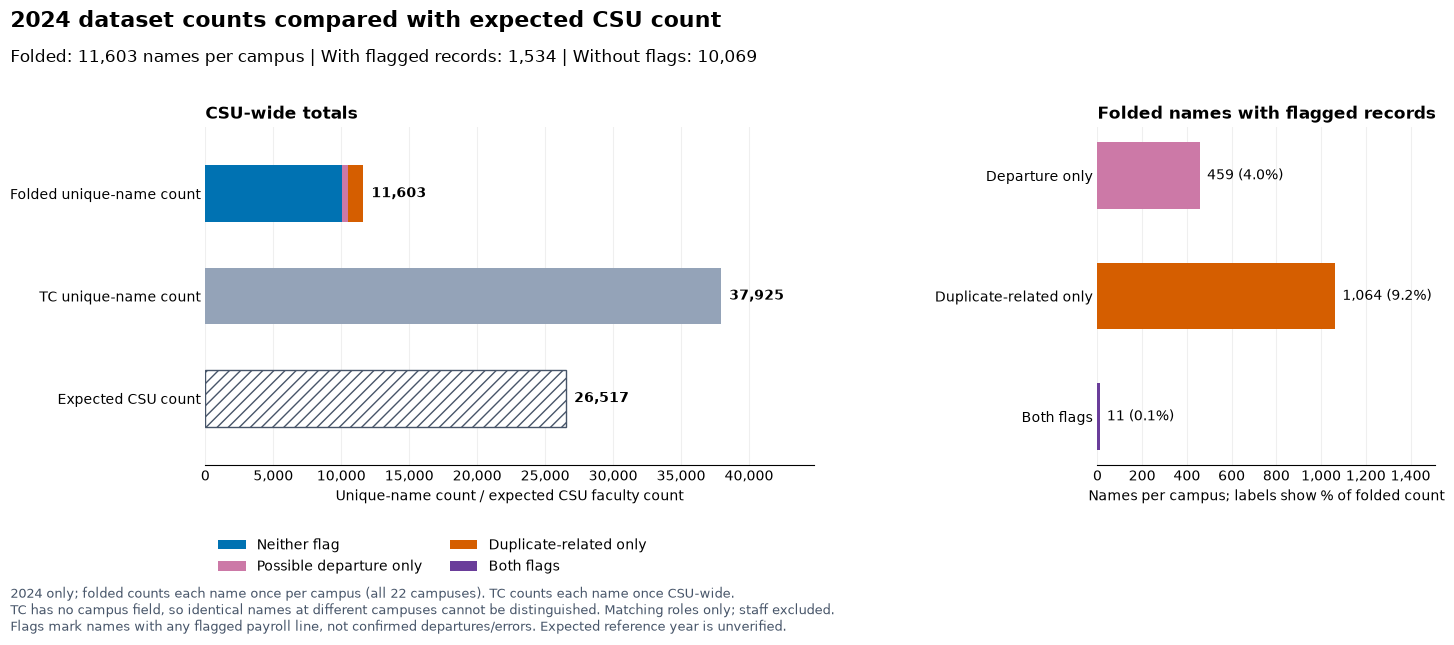

,source,count
0,Folded unique-name count,11603
1,TC unique-name count,37925
2,Expected CSU count,26517


,tc_unique_names
role,
clinical_adjunct_faculty,32
ladder_faculty,12343
lecturer,22278
postdoc,179
researcher_specialist_librarian,1731
supplemental_teaching_pay,12120
trainee,70


,names_per_campus
flag_class,
Neither flag,10069
Possible departure only,459
Duplicate-related only,1064
Both flags,11


In [73]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from matplotlib.patches import Patch

# Start with every 2024 folded CSU record, including unmatched salary rows.
system_folded = csu_df.loc[
    csu_df['source_system'].eq('CSU') & csu_df['year'].eq(2024)
].copy()
annual_keys = ['year', 'campus', 'name', 'matched_rank', 'salary_low', 'salary_high']
system_folded = system_folded.merge(
    departure_check[annual_keys + ['possible_departure']],
    on=annual_keys, how='left', validate='many_to_one',
)
valid = system_folded[['base_pay', 'salary_low', 'salary_high']].notna().all(axis=1)
in_range = valid & system_folded['base_pay'].between(
    system_folded['salary_low'], system_folded['salary_high']
).fillna(False)
system_folded['in_range'] = in_range
outside = valid & ~in_range
person_keys = ['year', 'campus', 'name']
group_size = system_folded.groupby(person_keys, dropna=False)['year'].transform('size')
companion = system_folded.groupby(person_keys, dropna=False)['in_range'].transform('any')
system_folded['departure_flag'] = (
    system_folded['possible_departure'].fillna(False).astype(bool) & outside
)
system_folded['duplicate_flag'] = group_size.gt(1) & companion & outside
# One name per campus/year; carry any flagged payroll line to that person.
system_people = (
    system_folded.dropna(subset=['name'])
    .groupby(person_keys, dropna=False, as_index=False)
    .agg(departure_flag=('departure_flag', 'any'), duplicate_flag=('duplicate_flag', 'any'))
)
system_people['flag_class'] = np.select(
    [system_people['departure_flag'] & system_people['duplicate_flag'],
     system_people['departure_flag'], system_people['duplicate_flag']],
    ['Both flags', 'Possible departure only', 'Duplicate-related only'],
    default='Neither flag',
)
classes = ['Neither flag', 'Possible departure only', 'Duplicate-related only', 'Both flags']
colors = ['#0072B2', '#CC79A7', '#D55E00', '#6A3D9A']
flag_counts = system_people['flag_class'].value_counts().reindex(classes, fill_value=0)
folded_total = len(system_people)
flagged_total = int(flag_counts.iloc[1:].sum())
# Match shared title categories: scraped titles and TC job wording differ.
folded_roles = system_folded['role'].dropna().unique()
tc_2024 = tc_df.loc[
    tc_df['year'].eq(2024) & tc_df['role'].isin(folded_roles)
].copy()
assert system_folded['year'].eq(2024).all(), 'Folded counts must use 2024 only.'
assert tc_2024['year'].eq(2024).all(), 'TC counts must use 2024 only.'
# TC has no campus field: unique names must be counted across the CSU system.
tc_total = tc_2024['name'].nunique()
# The reference CSV has no year column; its reference year cannot be filtered here.
expected_total = int(expected_faculty_counts['all_faculty'].sum())
csu_system_counts = pd.DataFrame({
    'source': ['Folded unique-name count', 'TC unique-name count', 'Expected CSU count'],
    'count': [folded_total, tc_total, expected_total],
})

# Shared zero baseline for totals; a separate panel makes small flags readable.
fig, (ax, detail) = plt.subplots(
    1, 2, figsize=(15, 6.5), gridspec_kw={'width_ratios': [1.8, 1]}
)
left = 0
for label, color in zip(classes, colors):
    value = int(flag_counts[label])
    ax.barh(0, value, left=left, color=color, height=0.55)
    left += value
ax.barh(1, tc_total, color='#94A3B8', height=0.55)
ax.barh(2, expected_total, facecolor='white', edgecolor='#475569',
        hatch='///', height=0.55)
for y, value in enumerate([folded_total, tc_total, expected_total]):
    ax.annotate(f'{value:,}', (value, y), xytext=(6, 0),
                textcoords='offset points', va='center', fontweight='bold')
ax.set_yticks([0, 1, 2], ['Folded unique-name count', 'TC unique-name count', 'Expected CSU count'])
ax.set_ylim(2.65, -0.65)
ax.set_xlim(0, max(folded_total, tc_total, expected_total) * 1.18)
ax.set_xlabel('Unique-name count / expected CSU faculty count')
ax.set_title('CSU-wide totals', loc='left', fontweight='bold')
ax.legend(handles=[Patch(facecolor=color, label=label)
                   for label, color in zip(classes, colors)],
          loc='upper left', bbox_to_anchor=(0, -0.18), ncol=2, frameon=False)

flag_values = flag_counts.iloc[1:]
bars = detail.barh(range(3), flag_values.to_numpy(), color=colors[1:], height=0.55)
detail.set_yticks(range(3), ['Departure only', 'Duplicate-related only', 'Both flags'])
detail.invert_yaxis()
detail.set_xlim(0, max(1, flag_values.max()) * 1.42)
detail.bar_label(bars, labels=[f'{value:,} ({value / folded_total:.1%})'
                              if folded_total else f'{value:,}'
                              for value in flag_values], padding=5, fontsize=10)
detail.set_title('Folded names with flagged records', loc='left', fontweight='bold')
detail.set_xlabel('Names per campus; labels show % of folded count')
for axis in [ax, detail]:
    axis.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    axis.set_axisbelow(True)
    axis.grid(axis='x', alpha=0.2)
    axis.tick_params(axis='both', length=0)
    axis.spines[['top', 'right', 'left']].set_visible(False)
fig.suptitle('2024 dataset counts compared with expected CSU count',
             x=0.02, ha='left', fontsize=16, fontweight='bold')
fig.text(0.02, 0.90,
         f'Folded: {folded_total:,} names per campus | With flagged records: {flagged_total:,} | '
         f'Without flags: {folded_total - flagged_total:,}',
         fontsize=12)
fig.text(0.02, 0.025,
         '2024 only; folded counts each name once per campus (all 22 campuses). TC counts each name once CSU-wide.\n'
         'TC has no campus field, so identical names at different campuses cannot be distinguished. Matching roles only; staff excluded.\n'
         'Flags mark names with any flagged payroll line, not confirmed departures/errors. Expected reference year is unverified.',
         fontsize=9, color='#475569')
fig.subplots_adjust(left=0.15, right=0.97, top=0.80, bottom=0.28, wspace=0.60)
plt.show()

display(csu_system_counts)
# Inspect exactly which title categories contribute to the TC comparison.
# Names can occur in multiple roles, so role counts need not sum to the TC total.
tc_matching_role_counts = tc_2024.groupby('role')['name'].nunique().rename('tc_unique_names').to_frame()
display(tc_matching_role_counts)
display(flag_counts.rename('names_per_campus').to_frame())


### How many outliers do the two flags cover?

This chart uses outliers as its denominator. It separates the remaining cases, possible departures, duplicate-related cases with an in-range companion, and cases with both flags. Instructor is omitted from the outlier graphics; its underlying records remain in the dataset.

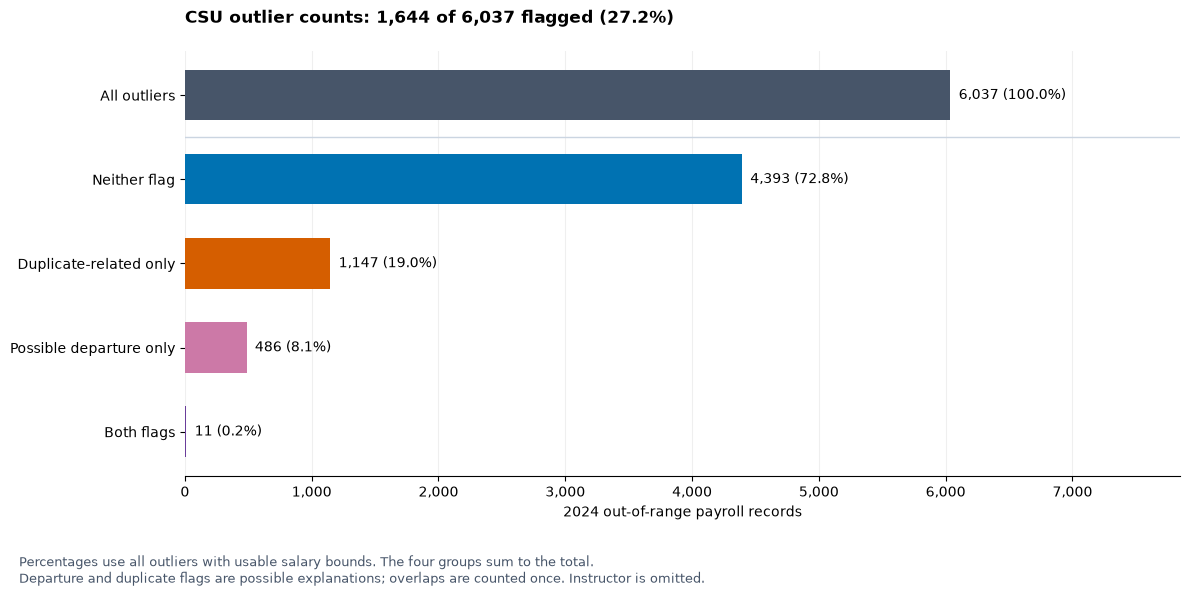

,category,count,pct_of_outliers
0,All outliers,6037,100.0
1,Neither flag,4393,72.8
2,Duplicate-related only,1147,19.0
3,Possible departure only,486,8.1
4,Both flags,11,0.2


In [74]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Use only outliers as the denominator, rather than every folded record.
outlier_records = combined_plot_df.loc[
    combined_plot_df['outside']
    & combined_plot_df['matched_rank'].str.casefold().ne('instructor')
].copy()
dep = outlier_records['departure_flag']
dup = outlier_records['duplicate_flag']
outlier_total = len(outlier_records)
flagged_outlier_total = int((dep | dup).sum())
outlier_count_summary = pd.DataFrame({
    'category': ['All outliers', 'Neither flag', 'Duplicate-related only',
                 'Possible departure only', 'Both flags'],
    'count': [outlier_total, int((~dep & ~dup).sum()), int((dup & ~dep).sum()),
              int((dep & ~dup).sum()), int((dep & dup).sum())],
})
outlier_count_summary['pct_of_outliers'] = (
    100 * outlier_count_summary['count'] / outlier_total if outlier_total else 0.0
)
flag_share = 100 * flagged_outlier_total / outlier_total if outlier_total else 0.0
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(outlier_count_summary['category'], outlier_count_summary['count'],
               color=['#475569', '#0072B2', '#D55E00', '#CC79A7', '#6A3D9A'], height=0.6)
ax.bar_label(bars, labels=[f'{r.count:,.0f} ({r.pct_of_outliers:.1f}%)'
                          for r in outlier_count_summary.itertuples(index=False)], padding=6)
ax.invert_yaxis()
ax.axhline(0.5, color='#CBD5E1', linewidth=1)
ax.set_xlim(0, max(1, outlier_total) * 1.3)
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.set(xlabel='2024 out-of-range payroll records', ylabel='')
ax.set_title(f'CSU outlier counts: {flagged_outlier_total:,} of {outlier_total:,} '
             f'flagged ({flag_share:.1f}%)', loc='left', fontweight='bold', pad=20)
ax.set_axisbelow(True)
ax.grid(axis='x', alpha=0.2)
ax.spines[['top', 'right', 'left']].set_visible(False)
fig.text(0.02, 0.02,
         'Percentages use all outliers with usable salary bounds. The four groups sum to the total.\n'
         'Departure and duplicate flags are possible explanations; overlaps are counted once. Instructor is omitted.',
         fontsize=9, color='#475569')
plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.show()
display(outlier_count_summary.round(1))


### University counts after accounting for repeated names

The dataset count is now distinct names per campus in 2024, not payroll rows. Multiple payments or appointments for the same name at the same campus count once. Both comparison charts share the same 21-campus totals and expected-count joins. Gap bars show unique-name dataset count minus expected CSU count, with percentage differences relative to expected. No departure flags are excluded. The name-based count can combine different people with identical names; the expected reference year remains unverified.

Both charts now recalculate totals through `audit_campus_unique_counts`, so rerunning this chart does not reuse an older chart's cached totals.

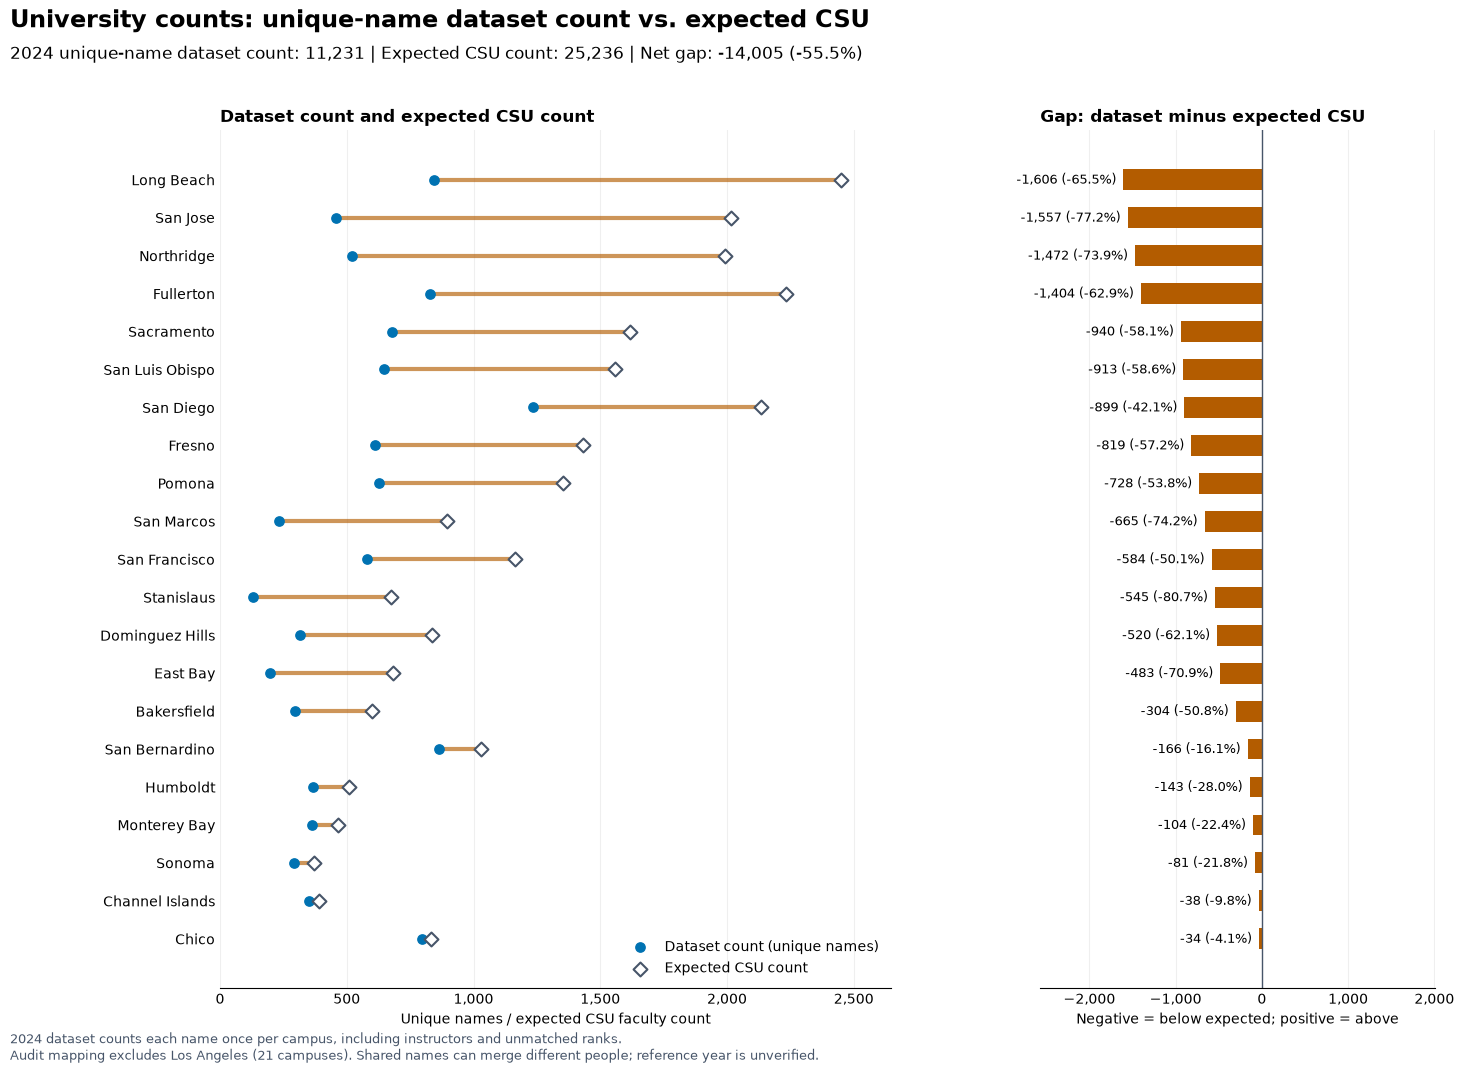

,dataset_count,expected_CSU_count,gap,gap_pct
count_campus_name,,,,
Long Beach,845,2451,-1606,-65.5
San Jose,459,2016,-1557,-77.2
Northridge,519,1991,-1472,-73.9
Fullerton,829,2233,-1404,-62.9
Sacramento,678,1618,-940,-58.1
San Luis Obispo,646,1559,-913,-58.6
San Diego,1234,2133,-899,-42.1
Fresno,613,1432,-819,-57.2
Pomona,626,1354,-728,-53.8


In [75]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import StrMethodFormatter

# Recalculate with the same function as the position chart, avoiding stale plot totals.
university_count_gaps = audit_campus_unique_counts(
    audit_folding_labels, audit_reference_counts
)
university_count_gaps['gap'] = (
    university_count_gaps['count'] - university_count_gaps['expected_count']
)
university_count_gaps['gap_pct'] = (
    100 * university_count_gaps['gap']
    / university_count_gaps['expected_count'].replace(0, np.nan)
)
university_count_gaps = university_count_gaps.sort_values('gap')
y = np.arange(len(university_count_gaps))
shortfall = university_count_gaps['gap'].lt(0)
gap_colors = np.where(shortfall, '#B35C00', '#00856A')
dataset_total = int(university_count_gaps['count'].sum())
reference_total = int(university_count_gaps['expected_count'].sum())
net_gap = dataset_total - reference_total
fig, (counts_ax, gap_ax) = plt.subplots(
    1, 2, figsize=(15, 11), sharey=True, gridspec_kw={'width_ratios': [1.7, 1]}
)
counts_ax.hlines(y, university_count_gaps['count'], university_count_gaps['expected_count'],
                 colors=gap_colors, linewidth=3, alpha=0.65)
counts_ax.scatter(university_count_gaps['count'], y, color='#0072B2', s=45,
                  zorder=3, label='Dataset count (unique names)')
counts_ax.scatter(university_count_gaps['expected_count'], y, marker='D',
                  facecolor='white', edgecolor='#475569', s=50, linewidth=1.5,
                  zorder=3, label='Expected CSU count')
counts_ax.set_yticks(y, university_count_gaps.index)
counts_ax.invert_yaxis()
counts_ax.set_xlim(0, university_count_gaps[['count', 'expected_count']].max().max() * 1.08)
counts_ax.set_title('Dataset count and expected CSU count', loc='left', fontweight='bold')
counts_ax.set_xlabel('Unique names / expected CSU faculty count')
counts_ax.legend(frameon=False, loc='lower right')
bars = gap_ax.barh(y, university_count_gaps['gap'], color=gap_colors, height=0.55)
gap_ax.axvline(0, color='#475569', linewidth=1)
limit = max(1, university_count_gaps['gap'].abs().max())
gap_ax.set_xlim(-limit * 1.6, limit * 1.25)
for pos, (_, row) in enumerate(university_count_gaps.iterrows()):
    gap_ax.annotate(f"{row['gap']:+,.0f} ({row['gap_pct']:+.1f}%)", (row['gap'], pos),
                    xytext=(-5 if row['gap'] < 0 else 5, 0), textcoords='offset points',
                    ha='right' if row['gap'] < 0 else 'left', va='center', fontsize=9)
gap_ax.set_title('Gap: dataset minus expected CSU', loc='left', fontweight='bold')
gap_ax.set_xlabel('Negative = below expected; positive = above')
gap_ax.tick_params(axis='y', labelleft=False)
for axis in [counts_ax, gap_ax]:
    axis.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    axis.set_axisbelow(True)
    axis.grid(axis='x', alpha=0.2)
    axis.tick_params(axis='both', length=0)
    axis.spines[['top', 'right', 'left']].set_visible(False)
fig.suptitle('University counts: unique-name dataset count vs. expected CSU',
             x=0.02, ha='left', fontsize=17, fontweight='bold')
fig.text(0.02, 0.935,
         f'2024 unique-name dataset count: {dataset_total:,} | Expected CSU count: {reference_total:,} | '
         f'Net gap: {net_gap:+,} ({100 * net_gap / reference_total:+.1f}%)', fontsize=12)
fig.text(0.02, 0.025,
         '2024 dataset counts each name once per campus, including instructors and unmatched ranks.\n'
         'Audit mapping excludes Los Angeles (21 campuses). Shared names can merge different people; reference year is unverified.',
         fontsize=9, color='#475569')
fig.subplots_adjust(left=0.16, right=0.97, top=0.87, bottom=0.09, wspace=0.28)
plt.show()
display(university_count_gaps.rename(columns={
    'count': 'dataset_count', 'expected_count': 'expected_CSU_count'
}).round(1))


In [76]:
csu_df[(csu_df['campus'] == 'Sonoma State University') & (csu_df['year'] == 2024)]

,year,campus,name,title,role,original_department,department,gross_pay,base_pay,overtime_pay,...,Step 29,Step 30,Step 31,Step 32,salary_match,salary_schedule_year,salary_range_mean,salary_low,salary_high,salary_expected
150920,2024,Sonoma State University,Aaron Westman,Lecturer AY,lecturer,Music Studio,Humanities & Languages,11937,4836,0,...,NaN,NaN,NaN,NaN,both,2024.0,6582.5,66084.0,91896.0,78990.0
150933,2024,Sonoma State University,Adam Hill,Instructional Faculty,ladder_faculty,Department of Counseling,Social Sciences & Communication,110638,101392,0,...,NaN,NaN,NaN,NaN,left_only,2024.0,<NA>,<NA>,<NA>,<NA>
150951,2024,Sonoma State University,Adam Zagelbaum,Instructional Faculty,ladder_faculty,Department of Counseling,Social Sciences & Communication,121450,108543,0,...,NaN,NaN,NaN,NaN,left_only,2024.0,<NA>,<NA>,<NA>,<NA>
150965,2024,Sonoma State University,Adele Santana,Instructional Faculty,ladder_faculty,Business Administration,"Business, Economics & Finance",140941,140379,0,...,NaN,NaN,NaN,NaN,left_only,2024.0,<NA>,<NA>,<NA>,<NA>
150983,2024,Sonoma State University,Aidong Hu,Instructional Faculty,ladder_faculty,Business Administration,"Business, Economics & Finance",148100,135206,0,...,NaN,NaN,NaN,NaN,left_only,2024.0,<NA>,<NA>,<NA>,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155464,2024,Sonoma State University,Young Min Chun,Instructional Faculty,supplemental_teaching_pay,Department of Kinesiology,Medicine & Health Sciences,0,0,0,...,NaN,NaN,NaN,NaN,left_only,2024.0,<NA>,<NA>,<NA>,<NA>
155476,2024,Sonoma State University,Zachary Sharrett,Lecturer AY,lecturer,Dept Chem Biochem Phys Astr,Science & Mathematics,95480,93980,0,...,NaN,NaN,NaN,NaN,both,2024.0,6582.5,66084.0,91896.0,78990.0
155497,2024,Sonoma State University,Zachary Wong,Instructional Faculty,ladder_faculty,Business Administration,"Business, Economics & Finance",0,0,0,...,NaN,NaN,NaN,NaN,left_only,2024.0,<NA>,<NA>,<NA>,<NA>
155498,2024,Sonoma State University,Zachary Wong,Instructional Faculty,ladder_faculty,Business Administration,"Business, Economics & Finance",222558,143521,0,...,NaN,NaN,NaN,NaN,left_only,2024.0,<NA>,<NA>,<NA>,<NA>
